# Fitting different signals to observed photonic lantern spectra

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

# Importing the necessary modules
from PLsim.otf import OTF
from PLsim.scene import Scene, SceneProjector
from PLsim.system.device import Device
from PLsim.system.lantern import generate_unitary_matrix

import hcipy as hc
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import pandas as pd
from tqdm import tqdm

# Custom modules
import functions
from PhotonicLanternDevice import PhotonicLanternDevice
from PhotonicLanternFitting import PhotonicLanternFitting

# Formatting the plots
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.titlesize'] = 20
plt.rcParams['figure.titleweight'] = 'bold'
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['axes.labelsize'] = 20
plt.rcParams['figure.labelsize'] = 20
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.title_fontsize'] = 16
plt.rcParams['legend.fontsize'] = 16
plt.rcParams['mathtext.fontset'] = 'cm'

## Defining constants

In [2]:
# Constants
MAS_TO_RAD = 1e-3/206265 # [rad/mas]

# Photonic lantern attributes
N_DIM = 65 # Number of pixels in pupil grid
DIAMETER = 10 # [m], diameter of telescope aperture for pupil
FOCAL_RESOLUTION = 1e-6 # [m], resolution of focal grid (make sure this samples LP modes enough but also not truncate the outer parts)
FOCAL_LENGTH = 40 # [m], focal length of telescope (initial value, OTF.from_fiber_params will find an optimal focal ratio)

# Fiber attributes
N_CORE = 1.444 # Index of refraction of the core
N_CLAD = 1.444 - 5.5e-3 # Index of refraction of the cladding
R_CORE = 10e-6 # [m], core radius

# Wavelengths
N_SPEC = 150 # Number of wavelength channels
WAV_MIDDLE = 1282.8 # [nm], Paschen beta line
WAV_WIDTH = 0.1 # [nm]
WAV_BANDWIDTH = 10*WAV_WIDTH # [nm]
WAV_RANGE = np.linspace(WAV_MIDDLE - WAV_BANDWIDTH/2, WAV_MIDDLE + WAV_BANDWIDTH/2, N_SPEC)

## Creating the photonic lantern model

In [3]:
photonic_lantern_device = PhotonicLanternDevice(
    N_DIM=N_DIM,
    DIAMETER=DIAMETER,
    FOCAL_RESOLUTION=FOCAL_RESOLUTION,
    WAV_MIDDLE=WAV_MIDDLE,
    N_CORE=N_CORE,
    N_CLAD=N_CLAD,
    R_CORE=R_CORE,
    FOCAL_LENGTH=FOCAL_LENGTH,
    N_SPEC=N_SPEC
)

fitter = PhotonicLanternFitting(photonic_lantern_device, WAV_RANGE)

Created pupil grid
Created focal grid

Fiber details:
n_core: 1.444
n_clad: 1.4385
r_core: 1e-05 m
ref_wavelength: 1.2828e-06 m

Created aperture
Supported modes:  ['LP01', 'LP11a', 'LP11b', 'LP21a', 'LP21b', 'LP02', 'LP31a', 'LP31b', 'LP12a', 'LP12b']
Number of modes:  10
Created optical transfer function

Computed optical transfer function

Generated unitary matrix of shape: (N_SPEC x N_OUTPUTS x N_OUTPUTS) -> (150, 10, 10)

Device initialized with:
  Lantern matrices: (150, 10, 10)
  PIC matrices: None
  Wavelengths: 150
Initialized device with the unitary matrix

Defined scene
Projected scene onto optical transfer function



## Creating spectra of the two stars

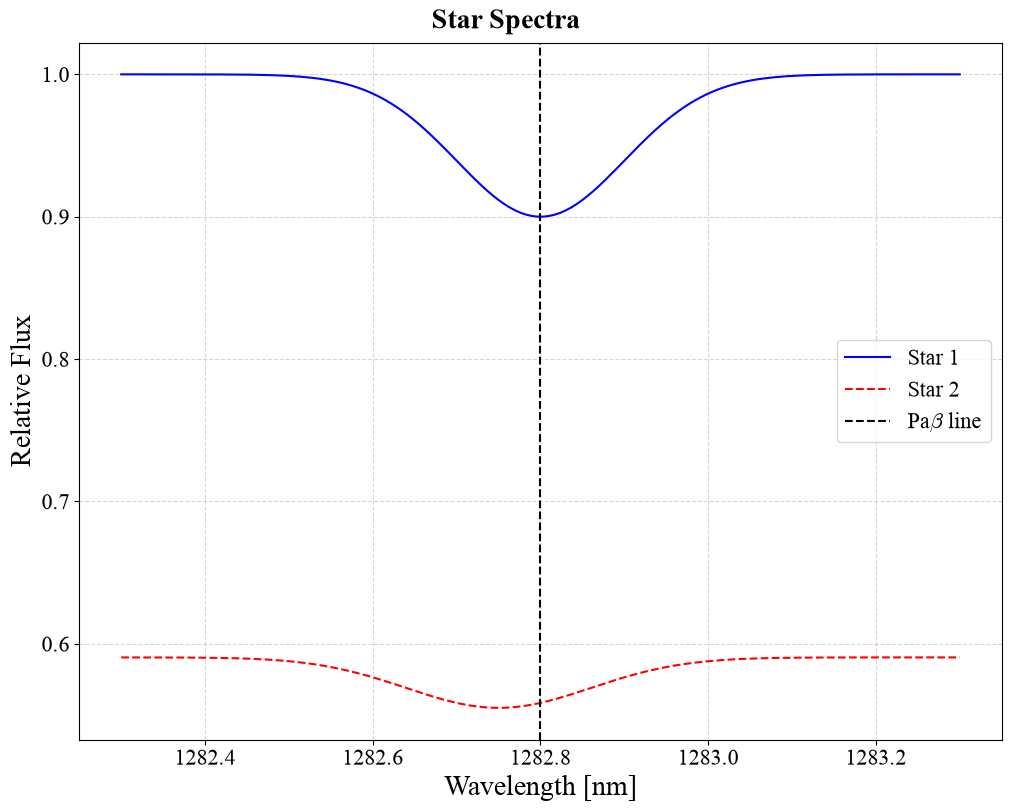

In [4]:
# Mass of the stars
M_1 = 1 # [M_1]
M_2 = 0.9 # [M_1]

# Flux of the continuum of the stars
F_1 = 1
F_2 = F_1 / functions.M_L_relation(M_1, M_2)

# Depth of the line
A_LINE_1 = 0.9
A_LINE_2 = 0.94

# Middle wavelength of each absorption line
WAV_MIDDLE_1 = WAV_MIDDLE
WAV_MIDDLE_2 = WAV_MIDDLE - 0.05

# Width of each absorption line
WAV_WIDTH_1 = WAV_WIDTH
WAV_WIDTH_2 = WAV_WIDTH + 0.01

# Spectrum of star 1
star1_spectrum = functions.create_spectrum(F_1, A_LINE_1, WAV_MIDDLE_1, WAV_WIDTH_1, WAV_RANGE)

# Spectrum of star 2
star2_spectrum = functions.create_spectrum(F_2, A_LINE_2, WAV_MIDDLE_2, WAV_WIDTH_2, WAV_RANGE)

# Plotting the spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Star Spectra')

ax.plot(WAV_RANGE, star1_spectrum, label='Star 1', color='b', linestyle='-')
ax.plot(WAV_RANGE, star2_spectrum, label='Star 2', color='r', linestyle='--')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

## Passing stars into the photonic lantern device

Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> (150, 10)


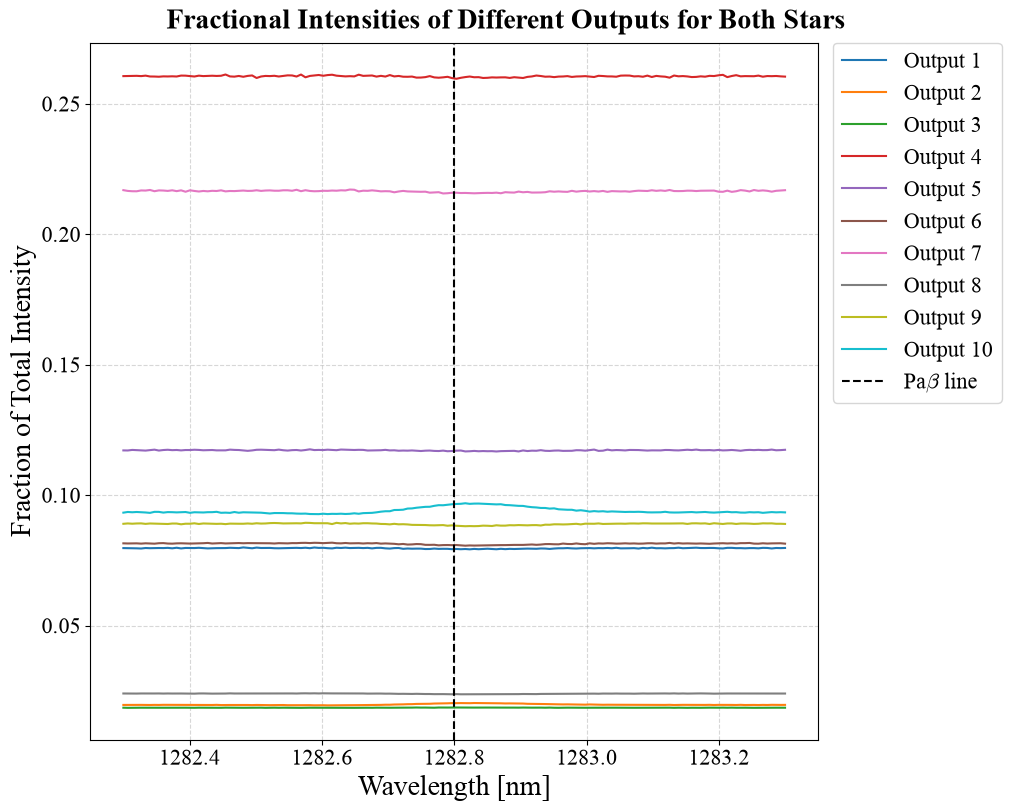

In [5]:
# Star 1 position
star1_x = 0
star1_y = 0
star1_position = np.array([star1_x, star1_y])

# Star 2 position
star2_x = 50
star2_y = 0
star2_position = np.array([star2_x, star2_y])

# Calculating photonic lantern outputs
combined_outputs = photonic_lantern_device.calculate_photonic_lantern_outputs(np.array([star1_position, star2_position]), np.array([star1_spectrum, star2_spectrum]), noise=1e-3)

# Computing the total intensities across all outputs as a function of wavelength
total_intensity = np.sum(combined_outputs, axis=1)

# Computing fractional intensities for the outputs
fractional_intensity = combined_outputs / total_intensity.reshape(-1, 1)

print(f'Shape of fractional intensities: (N_SPEC x N_OUTPUTS) -> {fractional_intensity.shape}')

fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Fractional Intensities of Different Outputs for Both Stars')

for i in range(photonic_lantern_device.N_PORTS):
    ax.plot(WAV_RANGE, fractional_intensity[:, i], label=f'Output {i+1}')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Fraction of Total Intensity')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0.)

plt.show()

## Fitting a single star to the observed photonic lantern outputs

In [6]:
result = fitter.single_fitting(fractional_intensity)

print(f'Global minimum position: {result.x} mas')
print(f'Global minimum error: {result.fun}')

Global minimum position: [-0.14584287  1.78550084] mas
Global minimum error: 1.3600880429966204


## Visualizing error surface

In [7]:
# Defining a grid to try pass into the optimization function
xs = np.linspace(-photonic_lantern_device.angular_extent, photonic_lantern_device.angular_extent, 100)
ys = np.linspace(-photonic_lantern_device.angular_extent, photonic_lantern_device.angular_extent, 100)

XS, YS = np.meshgrid(xs, ys)

# Passing each position into the optimization function
deltas = np.zeros_like(XS)

for i, x in enumerate(xs):
    for j, y in enumerate(ys):
        delta = fitter._single_star_objective((x, y), fractional_intensity)
        deltas[j, i] = delta

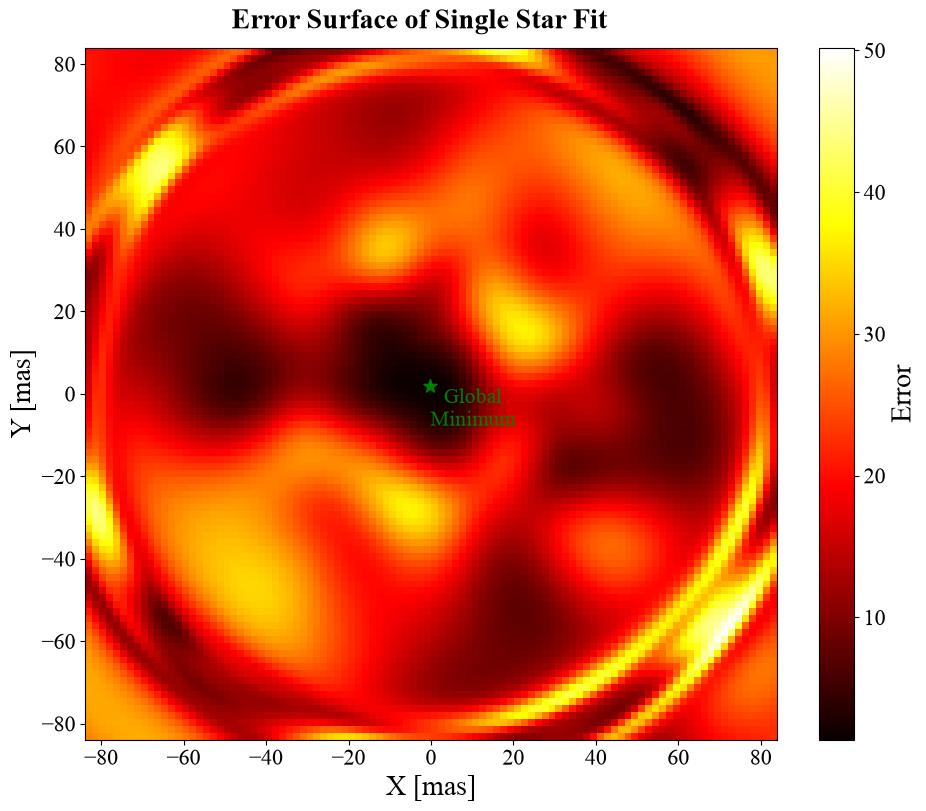

In [8]:
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Error Surface of Single Star Fit')

img = ax.imshow(deltas, origin='lower', extent=[xs[0], xs[-1], ys[0], ys[-1]], cmap='hot')

ax.scatter(result.x[0], result.x[1], marker='*', c='green', s=100)
ax.text(result.x[0], result.x[1], s='Global\nMinimum', fontsize=15, va='top', color='green', ma='center')

fig.colorbar(img, ax=ax, location='right', label=r'Error')

ax.set_xlabel('X [mas]')
ax.set_ylabel('Y [mas]')

ax.set_aspect('equal')

plt.show()

## Fitting a binary signal to the observed photonic lantern outputs
#### Four different stages:
1. Stage 1: Fit a single star like before using `scipy.optimize.differential_evolution` to get a starting point for Star 1.

2. Stage 2: Use the fitted single star position and a grid of Star 2 positions to find local minima and identify potential positions for Star 1 and Star 2 combined. This also solves the spectra using linear least squares.

3. Stage 3: Recover the spectra shapes by calculating the spectra using linear least squares for the optimized position found in Step 2. This will return the depth, center, and width of the spectra, as well as the mass of Star 2.

4. Refine all 12 fitted parameters with linear least squares to find parameter uncertainties and correlations.

In [9]:
guess = np.array([
    [0.8, WAV_MIDDLE + 0.1, WAV_WIDTH - 0.04],
    [0.7, WAV_MIDDLE - 0.05, WAV_WIDTH + 0.03]
])

true_values = np.array([
    star1_x, star1_y, star2_x, star2_y,
    F_1, A_LINE_1, WAV_MIDDLE_1, WAV_WIDTH_1,
    M_2, A_LINE_2, WAV_MIDDLE_2, WAV_WIDTH_2
])

final_results = fitter.binary_fitting(fractional_intensity, total_intensity, guess, M1=1, refine=True, true_values=true_values)

fitted_star1_x = final_results[0]
fitted_star1_y = final_results[1]
fitted_star2_x = final_results[2]
fitted_star2_y = final_results[3]
fitted_star1_F = final_results[4]
fitted_star1_depth = final_results[5]
fitted_star1_center = final_results[6]
fitted_star1_width = final_results[7]
fitted_M2 = final_results[8]
fitted_star2_depth = final_results[9]
fitted_star2_center = final_results[10]
fitted_star2_width = final_results[11]

Stage 1:    Position = [-0.146  1.785] mas
            SSR = 1.360e+00
            Time taken: 1.074 seconds

Single star fit result is not within tolerance of 0.001, continuing with binary fitting...



Binary fitting stage 2 (position fitting): 100%|██████████| 100/100 [00:33<00:00,  3.00it/s]


Stage 2:    Star 1 position = [0. 0.] mas
            Star 2 position = [49.996  0.   ] mas
            SSR = 7.550e-06
            Time taken: 33.346 seconds

Stage 3:    Star 1 line (continuum flux, depth, center, width) = [9.9990000e-01 9.0000000e-01 1.2828001e+03 9.9800000e-02]
            Star 2 line (continuum flux, depth, center, width) = [5.9040000e-01 9.4010000e-01 1.2827501e+03 1.0990000e-01]
            M_2 = 0.9000
            Time taken: 0.007 seconds

Stage 4:    Star 1 position = [0. 0.] mas
            Star 2 position = [49.996  0.   ] mas
            Star 1 line (continuum flux, depth, center, width) = [9.9990000e-01 9.0000000e-01 1.2828001e+03 9.9800000e-02]
            Star 2 line (depth, center, width) = [9.4010000e-01 1.2827501e+03 1.1020000e-01]
            M_2 = 0.9000
            SSR = 1.151e-05
            Time taken: 0.136 seconds

                                 fit  uncertainty    true
x1 [mas]                 0.000316914   0.00290925       0
y1 [mas]      

## Plotting the fitted binary spectra

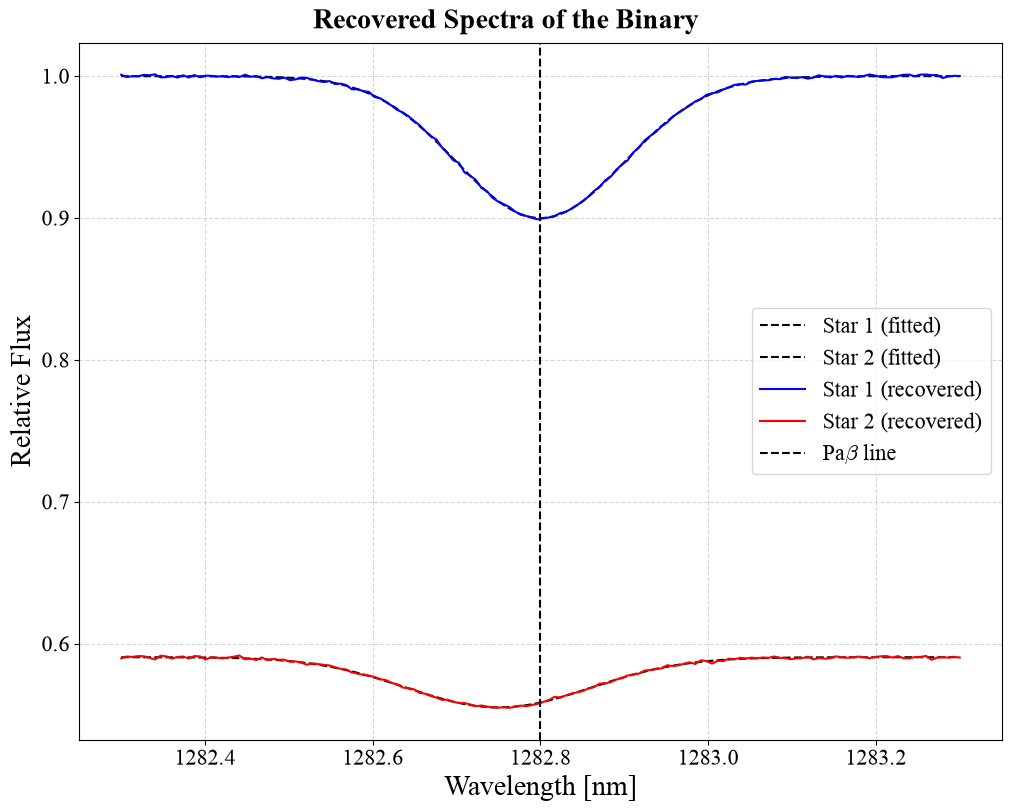

In [10]:
# Plotting the recovered spectra
fig = plt.figure()
fig.set_constrained_layout(True)
ax = fig.add_subplot()

fig.suptitle('Recovered Spectra of the Binary')

fitted_star1_spectrum = functions.create_spectrum(fitted_star1_F, fitted_star1_depth, fitted_star1_center, fitted_star1_width, WAV_RANGE)
fitted_star2_spectrum = functions.create_spectrum(fitted_star1_F / functions.M_L_relation(M_1, fitted_M2), fitted_star2_depth, fitted_star2_center, fitted_star2_width, WAV_RANGE)

ax.plot(WAV_RANGE, fitted_star1_spectrum, color='k', label='Star 1 (fitted)', linestyle='--')
ax.plot(WAV_RANGE, fitted_star2_spectrum, color='k', label='Star 2 (fitted)', linestyle='--')

# ax.plot(WAV_RANGE, star1_spectrum, color='b', label='Star 1 (true)', linestyle='-')
# ax.plot(WAV_RANGE, star2_spectrum, color='r', label='Star 2 (true)', linestyle='-')

ax.plot(WAV_RANGE, fitter.recovered_s1, color='b', label='Star 1 (recovered)', linestyle='-')
ax.plot(WAV_RANGE, fitter.recovered_s2, color='r', label='Star 2 (recovered)', linestyle='-')

ax.axvline(WAV_MIDDLE, color='k', linestyle='--', label='Pa$\\beta$ line')

ax.set_xlabel('Wavelength [nm]')
ax.set_ylabel('Relative Flux')

ax.grid(True, linestyle='--', alpha=0.5)

ax.legend()

plt.show()

In [13]:
G_x = photonic_lantern_device.scene_projector.compute_point(0 * photonic_lantern_device.MAS_TO_RAD, 30 * photonic_lantern_device.MAS_TO_RAD)
print(G_x.shape)

(10, 10, 1)
